In [1]:
import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)
import re
import pickle
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm.auto import tqdm
import time

import torch
import torch.nn as nn
import torch.nn.functional as F

import warnings
warnings.filterwarnings('ignore')

# pd.set_option('display.max_colwidth', None)

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

import kagglehub

/kaggle/input/competitions/smart-mcq-solver-challenge/sample_submission.csv
/kaggle/input/competitions/smart-mcq-solver-challenge/train.csv
/kaggle/input/competitions/smart-mcq-solver-challenge/test.csv


# Knowing the problem 

Smart MCQ Solver Challenge
Build AI systems that  predict top 3 correct answers for challenging multiple choice questions

- we are given prompts and 5 options our model should predict answers in top -3 fashion 

# Import datasets

In [2]:
train = pd.read_csv("/kaggle/input/competitions/smart-mcq-solver-challenge/train.csv")
test = pd.read_csv("/kaggle/input/competitions/smart-mcq-solver-challenge/test.csv")
df = train.copy()
test_df = test.copy()
print(train.shape)
print(test.shape)

(2000, 8)
(500, 7)


# Setup HuggingFace and WandB Tokens

In [3]:
from kaggle_secrets import UserSecretsClient
user_secrets = UserSecretsClient()
secret_value_0 = user_secrets.get_secret("HF_TOKEN")
secret_value_1 = user_secrets.get_secret("WANDB_API_KEY")


In [4]:
import wandb


os.environ["WANDB_ENTITY"] = "23f3003322-indian-institute-of-technology-madras"
os.environ["WANDB_PROJECT"] = "23f3003322-t22026"

wandb.login(key=secret_value_1)

wandb: WARNING If you're specifying your api key in code, ensure this code is not shared publicly.
wandb: WARNING Consider setting the WANDB_API_KEY environment variable, or running `wandb login` from the command line.
wandb: [wandb.login()] Using explicit session credentials for https://api.wandb.ai.
wandb: Appending key for api.wandb.ai to your netrc file: /root/.netrc
wandb: W&B API key is configured. Use `wandb login --relogin` to force relogin


True

# Basic EDA 

Lets start with looking into the data

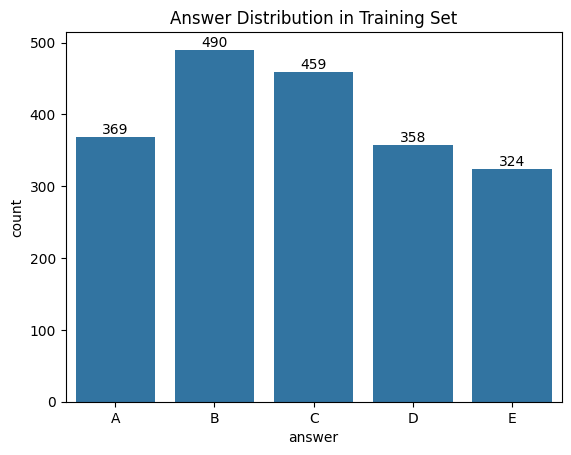

answer
A    0.1845
B    0.2450
C    0.2295
D    0.1790
E    0.1620
Name: proportion, dtype: float64


In [5]:
ax = sns.countplot(data=df, x='answer', order=['A','B','C','D','E'])
ax.bar_label(ax.containers[0])
plt.title("Answer Distribution in Training Set")
plt.show()

# Proportion
print(df['answer'].value_counts(normalize=True).sort_index())

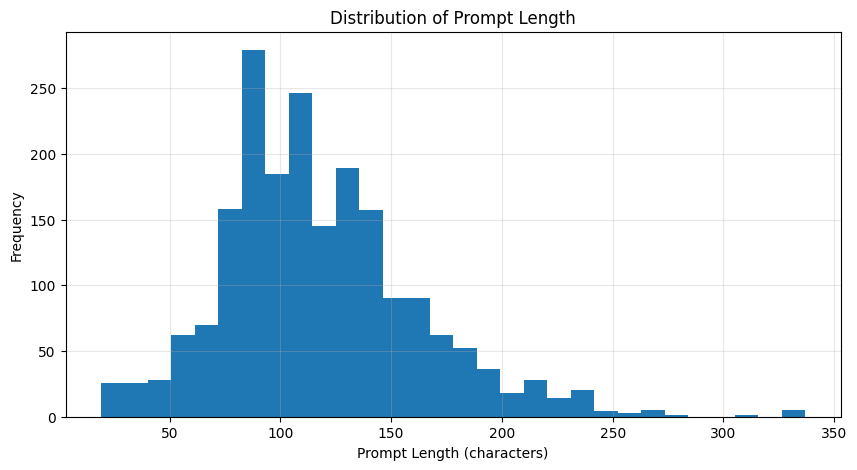

In [6]:
df["prompt_len"] = df["prompt"].str.len()

df["prompt_len"].describe()

plt.figure(figsize=(10, 5))
plt.hist(df["prompt_len"], bins=30)

plt.title("Distribution of Prompt Length")
plt.xlabel("Prompt Length (characters)")
plt.ylabel("Frequency")

plt.grid(alpha=0.3)
plt.show()

The graph is slightly right skewed with most of the frequency between 50 - 200 chars.

lets look into the **Prompts**

In [7]:
df[df["prompt"].duplicated()]

,id,prompt,A,B,C,D,E,answer,prompt_len
112,113,Select the most accurate option: What are the ...,"They are unknown, but possibilities include la...",They are known to be black holes and Preon stars.,They are only MACHOs.,They are clusters of brown dwarfs.,They are new particles such as RAMBOs.,A,79
120,121,Pick the best possible answer: What is the met...,8 times more than the Sun,8 times less than the Sun,13 light years away from Earth,Unknown,Equal to the Sun,B,89
209,210,Select the most accurate option: What is the r...,The surface charge on a conductor depends on t...,The surface charge on a conductor depends on t...,The surface charge on a conductor depends on t...,The surface charge on a conductor depends on t...,The surface charge on a conductor depends on t...,D,214
238,239,Choose the correct answer: What is water hamme...,Water hammer is a type of water turbine used i...,Water hammer is a type of air trap or standpip...,Water hammer is a type of plumbing tool used t...,Water hammer is a type of water pump used to b...,Water hammer is a loud banging noise resemblin...,E,76
258,259,Identify the correct statement: What is the ef...,"An electric field, precisely aligned with the ...","A magnetic field, randomly aligned with the sp...","A magnetic field, precisely aligned with the s...","A gravitational field, randomly aligned with t...","A gravitational field, precisely aligned with ...",C,116
...,...,...,...,...,...,...,...,...,...
1973,1974,Determine the correct option: What is reciproc...,Reciprocal length or inverse length is a quant...,Reciprocal length or inverse length is a quant...,Reciprocal length or inverse length is a quant...,Reciprocal length or inverse length is a quant...,Reciprocal length or inverse length is a quant...,E,85
1978,1979,Which of the following is correct? What is the...,Class L dwarfs are hotter than M stars and are...,Class L dwarfs are cooler than M stars and are...,Class L dwarfs are hotter than M stars and are...,Class L dwarfs are cooler than M stars and are...,Class L dwarfs are cooler than M stars and are...,B,164
1981,1982,Pick the best possible answer: What was Isaac ...,Isaac Newton rejected the wave concept of ligh...,Isaac Newton rejected the wave principle of li...,Isaac Newton accepted the wave principle of li...,Isaac Newton rejected the wave framework of li...,Isaac Newton accepted the wave concept of ligh...,D,130
1992,1993,Identify the correct statement: What is the se...,The second law of thermodynamics is a physical...,The second law of thermodynamics is a physical...,The second law of thermodynamics is a physical...,The second law of thermodynamics is a physical...,The second law of thermodynamics is a physical...,E,101


242 / 2000 are duplicated cols

In [8]:
same = different = shown = 0

for prompt, group in df.groupby("prompt"):
    if len(group) < 2:
        continue

    identical = group[["A", "B", "C", "D", "E", "answer"]].nunique().eq(1).all()

    if identical:
        same += 1
    else:
        different += 1

        if shown < 3:
            print("=" * 80)
            print(f"Prompt: {prompt}")
            display(group[["prompt", "A", "B", "C", "D", "E", "answer"]])
            shown += 1

print(f"Duplicate prompts with identical options & answer : {same}")
print(f"Duplicate prompts with differences                : {different}")

Prompt: Choose the correct answer: What is Modified Newtonian Dynamics (MOND)? based on the given context.


,prompt,A,B,C,D,E,answer
291,Choose the correct answer: What is Modified Ne...,MOND is a framework that explains the behavior...,MOND is a hypothesis that proposes a modificat...,MOND is a hypothesis that proposes a modificat...,MOND is a hypothesis that proposes a modificat...,MOND is a principle that explains the behavior...,C
848,Choose the correct answer: What is Modified Ne...,MOND is a principle that explains the behavior...,MOND is a hypothesis that proposes a modificat...,MOND is a hypothesis that proposes a modificat...,MOND is a hypothesis that proposes a modificat...,MOND is a principle that explains the behavior...,C


Prompt: Choose the correct answer: What is a planetary mechanism? based on the given context.


,prompt,A,B,C,D,E,answer
162,Choose the correct answer: What is a planetary...,A mechanism of planets that are all located in...,A framework of planets that are all the same s...,Any set of gravitationally bound non-stellar o...,A structure of planets that are all located in...,A structure of planets that are all made of gas.,C
1944,Choose the correct answer: What is a planetary...,A mechanism of planets that are all located in...,A framework of planets that are all the same s...,Any set of gravitationally bound non-stellar o...,A framework of planets that are all located in...,A framework of planets that are all made of gas.,C


Prompt: Choose the correct answer: What is a planetary structure? based on the given context.


,prompt,A,B,C,D,E,answer
146,Choose the correct answer: What is a planetary...,A framework of planets that are all located in...,A framework of planets that are all the same s...,Any set of gravitationally bound non-stellar o...,A mechanism of planets that are all located in...,A structure of planets that are all made of gas.,C
545,Choose the correct answer: What is a planetary...,A mechanism of planets that are all located in...,A mechanism of planets that are all the same s...,Any set of gravitationally bound non-stellar o...,A framework of planets that are all located in...,A framework of planets that are all made of gas.,C


Duplicate prompts with identical options & answer : 158
Duplicate prompts with differences                : 54


here we can observe

- Duplicate prompts with identical options & answer : 158
- Duplicate prompts with differences                : 54

even in those 54 changes are just one word like
"A structure" Vs "A framework" Vs "A principle"

Clean question starting phrases

In [9]:
qstrings=[
    "Pick the best possible answer:",
    "Determine the correct option:",
    "Select the most accurate option:",
    "Identify the correct statement:",
    "Choose the correct answer:",
    "Which of the following is correct?",
]

qstrings = [q.lower() for q in qstrings]

pattern = r"^(" + "|".join(map(re.escape, qstrings)) + r")\s*"

df["prompt"] = (
    df["prompt"]
    .str.lower()
    .str.replace(pattern, "", regex=True)
    .str.strip()
)

In [10]:
df[df["prompt"].duplicated()]

,id,prompt,A,B,C,D,E,answer,prompt_len
47,48,what is the liouville density? among the liste...,The Liouville density is a probability distrib...,The Liouville density is a quasiprobability di...,The Liouville density is a bounded probability...,The Liouville density is a probability distrib...,The Liouville density is a probability distrib...,A,83
71,72,what is martin heidegger's view on the relatio...,Martin Heidegger believes that humans exist wi...,Martin Heidegger believes that humans do not e...,Martin Heidegger does not believe in the exist...,Martin Heidegger believes that the relationshi...,Martin Heidegger believes that time is an illu...,B,146
110,111,what is the significance of probability amplit...,Probability amplitudes are used to determine t...,Probability amplitudes have no significance in...,Probability amplitudes are used to determine t...,Probability amplitudes act as the equivalent o...,Probability amplitudes act as the equivalent o...,E,72
112,113,what are the constituents of cold dark matter?,"They are unknown, but possibilities include la...",They are known to be black holes and Preon stars.,They are only MACHOs.,They are clusters of brown dwarfs.,They are new particles such as RAMBOs.,A,79
116,117,what is the definition of an improper rotation...,An improper rotation is the combination of a r...,An improper rotation is the combination of a r...,An improper rotation is the combination of a r...,An improper rotation is the combination of a r...,An improper rotation is the combination of a r...,B,106
...,...,...,...,...,...,...,...,...,...
1994,1995,what is the kutta condition? among the listed ...,The Kutta condition is a physical requirement ...,The Kutta condition is a physical requirement ...,The Kutta condition is a mathematical requirem...,The Kutta condition is a mathematical requirem...,The Kutta condition is a physical requirement ...,A,87
1995,1996,what is the piezoelectric strain coefficient f...,d = 1.9·10‑12 m/V,d = 3.1·10‑12 m/V,d = 4.2·10‑12 m/V,d = 2.5·10‑12 m/V,d = 5.8·10‑12 m/V,B,72
1997,1998,what does earnshaw's theorem state? from the f...,A collection of point charges can be maintaine...,A collection of point charges can be maintaine...,A collection of point charges can be maintaine...,A collection of point charges cannot be mainta...,A collection of point charges can be maintaine...,D,93
1998,1999,what is the revised view of the atmosphere's n...,The atmosphere is a mechanism that is only inf...,"The atmosphere possesses both chaos and order,...",The atmosphere is a structure that is only inf...,The atmosphere is a completely chaotic mechani...,The atmosphere is a completely ordered structu...,B,266


thats 1074 rows out of 2000.

Lets do the same on test data too

In [11]:
test_df["prompt"] = (
    test_df["prompt"]
    .str.lower()
    .str.replace(pattern, "", regex=True)
    .str.strip()
)

In [12]:
test_df[test_df["prompt"].duplicated()]

,id,prompt,A,B,C,D,E
60,61,what is a regular polytope?,A regular polytope is a geometric shape whose ...,A regular polytope is a geometric shape whose ...,A regular polytope is a geometric shape whose ...,A regular polytope is a geometric shape whose ...,A regular polytope is a geometric shape whose ...
62,63,what is the relationship between the wigner fu...,"The Wigner function W(x, p) is the Wigner tran...","The Wigner function W(x, p) is a source functi...","The Wigner function W(x, p) is the derivative ...","The Wigner function W(x, p) represents the Ham...","The Wigner function W(x, p) is the time deriva..."
66,67,what is the ozma problem?,The Ozma Problem is a chapter in a book that d...,The Ozma Problem is a discussion about time in...,The Ozma Problem is a conundrum that examines ...,The Ozma Problem is a measure of how symmetry ...,The Ozma Problem is a comparison between the l...
70,71,what is the purpose of measuring the larmor pr...,To measure the magnetization in the same direc...,To create a T1-weighted image that is useful f...,To obtain sufficient signal quality in the mic...,To measure the independent relaxation processe...,To change the repetition time (TR) and obtain ...
91,92,what was the aim of the gravity probe b (gp-b)...,To prove that pressure contributes equally to ...,"To measure spacetime curvature near Earth, wit...",To measure the distribution of Fe and Al on th...,To confirm the relatively large geodetic effec...,To measure the discrepancy between active and ...
...,...,...,...,...,...,...,...
488,489,what is minkowski space?,Minkowski space is a physical space where obje...,Minkowski space is a mathematical model that c...,Minkowski space is a mathematical model that c...,Minkowski space is a mathematical model that c...,Minkowski space is a physical space where obje...
491,492,what is the main focus of the environmental sc...,"Environmental studies, with a main focus on ma...","Environmental studies, with a main focus on ma...","Environmental studies, with a main focus on ma...","Environmental studies, with a main focus on ma...","Environmental studies, with a main focus on sp..."
497,498,what is magnetic susceptibility?,Magnetic susceptibility is a measure of how mu...,Magnetic susceptibility is a measure of how mu...,Magnetic susceptibility is a measure of how mu...,Magnetic susceptibility is a measure of how mu...,Magnetic susceptibility is a measure of how mu...
498,499,what is the evidence for the existence of a su...,The Milky Way galaxy has a supermassive black ...,The Milky Way galaxy has a supermassive black ...,The Milky Way galaxy has a supermassive black ...,The Milky Way galaxy has a supermassive black ...,The star S2 follows an elliptical orbit with a...


89/ 500 are duplicates 

In [13]:
overlap_count = len(set(df["prompt"]).intersection(set(test_df["prompt"])))

print(f"Number of overlapping prompts: {overlap_count}")

Number of overlapping prompts: 363


there are 363 prompts in test data that are exactly the same of training data 

Lets look at their options

In [14]:
train_unique = df.drop_duplicates(subset=["prompt"]).copy()
test_unique = test_df.drop_duplicates(subset=["prompt"]).copy()

# Merge the two datasets on the overlapping prompts
overlap_df = pd.merge(
    train_unique, 
    test_unique, 
    on="prompt", 
    suffixes=('_train', '_test')
)

# functions to check option matching
def check_exact_match(row):
    """Checks if A=A, B=B, C=C, D=D, E=E"""
    return (row['A_train'] == row['A_test'] and
            row['B_train'] == row['B_test'] and
            row['C_train'] == row['C_test'] and
            row['D_train'] == row['D_test'] and
            row['E_train'] == row['E_test'])

def check_shuffled_match(row):
    """Checks if the 5 options are the same text, just in a different order"""
    train_opts = set([row['A_train'], row['B_train'], row['C_train'], row['D_train'], row['E_train']])
    test_opts = set([row['A_test'], row['B_test'], row['C_test'], row['D_test'], row['E_test']])
    return train_opts == test_opts

overlap_df['exact_match'] = overlap_df.apply(check_exact_match, axis=1)
overlap_df['shuffled_match'] = overlap_df.apply(check_shuffled_match, axis=1)

total_overlaps = len(overlap_df)
exact_count = overlap_df['exact_match'].sum()
shuffled_only_count = overlap_df['shuffled_match'].sum() - exact_count
different_count = total_overlaps - overlap_df['shuffled_match'].sum()

print(f"Total Unique Overlapping Prompts: {total_overlaps}")
print(f"-> EXACT Match (Options are identical): {exact_count}")
print(f"-> SHUFFLED Match (Same options, different order): {shuffled_only_count}")
print(f"-> DIFFERENT Options (At least one option text changed): {different_count}")

Total Unique Overlapping Prompts: 363
-> EXACT Match (Options are identical): 304
-> SHUFFLED Match (Same options, different order): 0
-> DIFFERENT Options (At least one option text changed): 59


In [15]:
# Isolate the 59 questions where options are different
mismatched_df = overlap_df[(~overlap_df['exact_match']) & (~overlap_df['shuffled_match'])].copy()

def check_answer_survival(row):
    """
    Finds the text of the correct answer in the train set,
    and checks if that text exists in ANY of the test set options.
    """
    # Identify which letter was the correct answer in the train set
    correct_letter = row['answer']
    
    # Get the actual text of that correct answer
    correct_text = str(row[f"{correct_letter}_train"]).strip().lower()
    
    # Gather all 5 option texts from the TEST set
    test_options = [
        str(row['A_test']).strip().lower(),
        str(row['B_test']).strip().lower(),
        str(row['C_test']).strip().lower(),
        str(row['D_test']).strip().lower(),
        str(row['E_test']).strip().lower()
    ]
    
    # Check if the correct text is in the test options
    return correct_text in test_options

mismatched_df['answer_survived'] = mismatched_df.apply(check_answer_survival, axis=1)

survived_count = mismatched_df['answer_survived'].sum()
vanished_count = len(mismatched_df) - survived_count

print(f"Total Mismatched Questions: {len(mismatched_df)}")
print(f"-> The original correct answer SURVIVED in the test set: {survived_count}")
print(f"-> The original correct answer VANISHED entirely: {vanished_count}")

Total Mismatched Questions: 59
-> The original correct answer SURVIVED in the test set: 32
-> The original correct answer VANISHED entirely: 27


Out of 363 Unique Overlapping Prompts ,
- EXACT Match (Options are identical): 304
- SHUFFLED Match (Same options, different order): 0
- DIFFERENT Options (At least one option text changed): 59

out of 59 mismatched questions:
- The original correct answer SURVIVED in the test set: 32
- The original correct answer VANISHED entirely: 27

# Preprocessing


In [16]:
train["prompt"] = (
    train["prompt"]
    .str.lower()
    .str.replace(pattern, "", regex=True)
    .str.strip()
)

test["prompt"] = (
    test["prompt"]
    .str.lower()
    .str.replace(pattern, "", regex=True)
    .str.strip()
)

train_clean = train.drop_duplicates(
    subset=["prompt"],
    keep="first"
).reset_index(drop=True)


train_full = train.copy().reset_index(drop=True)

print("Original :", train.shape)
print("Clean    :", train_clean.shape)
print("Full     :", train_full.shape)
print("Test     :", test.shape)

Original : (2000, 8)
Clean    : (926, 8)
Full     : (2000, 8)
Test     : (500, 7)


In [17]:
# encoding 

label2id = { 
    "A":0,
    "B":1,
    "C":2,
    "D":3,
    "E":4
}

id2label = {
    v:k for k,v in label2id.items()
}

train_clean["label"] = train_clean["answer"].map(label2id)
train_full["label"] = train_full["answer"].map(label2id)

print(train_clean[["answer","label"]].head())

  answer  label
0      B      1
1      A      0
2      C      2
3      B      1
4      A      0


# model 1 : scratch model

BiLSTM + Attention

In [18]:

# Model 1 Configuration - BiLSTM + Attention

BILSTM_CFG = {

    # Vocabulary
    "min_freq": 2,
    "max_vocab_size": 30000,

    # Sequence
    "max_length": 128,

    # Embedding
    "embedding_dim": 300,

    # BiLSTM
    "hidden_dim": 256,
    "num_layers": 5,
    "bidirectional": True,

    # Regularization
    "dropout": 0.1,

    # Training
    "batch_first":True,
    "batch_size": 16,
    "epochs": 15,
    "learning_rate": 1e-3,
    "weight_decay": 1e-5,

    "device": torch.device("cuda" if torch.cuda.is_available() else "cpu")
}

print(BILSTM_CFG)

{'min_freq': 2, 'max_vocab_size': 30000, 'max_length': 128, 'embedding_dim': 300, 'hidden_dim': 256, 'num_layers': 5, 'bidirectional': True, 'dropout': 0.1, 'batch_first': True, 'batch_size': 16, 'epochs': 15, 'learning_rate': 0.001, 'weight_decay': 1e-05, 'device': device(type='cuda')}


## Train validation split

In [19]:
from sklearn.model_selection import train_test_split

In [20]:
bilstm_train_df, bilstm_valid_df = train_test_split(
    train_clean,
    test_size=0.20,
    random_state=42,
    stratify=train_clean["label"]
)

bilstm_train_df = bilstm_train_df.reset_index(drop=True)
bilstm_valid_df = bilstm_valid_df.reset_index(drop=True)

print("=" * 60)
print(f"Training Samples   : {len(bilstm_train_df)}")
print(f"Validation Samples : {len(bilstm_valid_df)}")
print("=" * 60)

print("\nTraining Label Distribution")
print(bilstm_train_df["answer"].value_counts().sort_index())

print("\nValidation Label Distribution")
print(bilstm_valid_df["answer"].value_counts().sort_index())

Training Samples   : 740
Validation Samples : 186

Training Label Distribution
answer
A    142
B    177
C    165
D    134
E    122
Name: count, dtype: int64

Validation Label Distribution
answer
A    36
B    45
C    41
D    33
E    31
Name: count, dtype: int64


## scratch Vocabulary

In [21]:
from collections import Counter

def tokenizer(text):
    """
    Simple scratch tokenizer.
    Lowercases text and extracts words, numbers and <SEP>.
    """

    text = text.lower()

    return re.findall(r"<sep>|[a-z0-9']+", text)



class ScratchVocabulary:

    def __init__(self, min_freq=BILSTM_CFG["min_freq"]):

        self.min_freq = min_freq

        self.word2idx = {
            "<PAD>": 0,
            "<UNK>": 1,
            "<SEP>": 2
        }

        self.idx2word = {
            0: "<PAD>",
            1: "<UNK>",
            2: "<SEP>"
        }

        self.vocab_size = 3

    def build_vocab(self, texts):

        counter = Counter()

        for text in texts:

            tokens = tokenizer(text)

            counter.update(tokens)

        for word, freq in counter.items():

            if freq >= self.min_freq:

                if word not in self.word2idx:

                    self.word2idx[word] = self.vocab_size

                    self.idx2word[self.vocab_size] = word

                    self.vocab_size += 1

    def numericalize(self, text):

        tokens = tokenizer(text)

        return [
            self.word2idx.get(token, self.word2idx["<UNK>"])
            for token in tokens
        ]

In [22]:
def clean_text(text):
    """
    Simple text normalization for the scratch model.
    """

    text = str(text).lower()

    # Collapse multiple spaces
    text = re.sub(r"\s+", " ", text)

    return text.strip()

In [23]:
# Build Vocabulary from Training Set

all_text = []
OPTION_COLS = ["A", "B", "C", "D", "E"]

for _, row in bilstm_train_df.iterrows():

    all_text.append(clean_text(row["prompt"]))

    for option in OPTION_COLS:

        all_text.append(clean_text(row[option]))

vocab = ScratchVocabulary(
    min_freq=BILSTM_CFG["min_freq"]
)

vocab.build_vocab(all_text)

print("=" * 60)
print(f"Vocabulary Size : {vocab.vocab_size}")
print("=" * 60)

Vocabulary Size : 2961


In [24]:
from torch.utils.data import Dataset


class BiLSTMMCQDataset(Dataset):

    def __init__(
        self,
        dataframe,
        vocab,
        max_length,
        is_test=False
    ):

        self.df = dataframe.reset_index(drop=True)

        self.vocab = vocab

        self.max_length = max_length

        self.is_test = is_test

    def __len__(self):

        return len(self.df)

    def pad_sequence(self, tokens):

        if len(tokens) > self.max_length:

            tokens = tokens[:self.max_length]

        else:

            tokens = tokens + [self.vocab.word2idx["<PAD>"]] * (self.max_length - len(tokens))

        return tokens

    def __getitem__(self, idx):

        row = self.df.iloc[idx]

        prompt = clean_text(row["prompt"])

        option_sequences = []

        for option in OPTION_COLS:

            option_text = clean_text(row[option])

            # Prompt <SEP> Option
            combined = (
                prompt
                + " <SEP> "
                + option_text
            )

            token_ids = self.vocab.numericalize(combined)

            token_ids = self.pad_sequence(token_ids)

            option_sequences.append(token_ids)

        option_sequences = torch.tensor(
            option_sequences,
            dtype=torch.long
        )

        if self.is_test:

            return option_sequences, row["id"]

        label = torch.tensor(
            label2id[row["answer"]],
            dtype=torch.long
        )

        return option_sequences, label

In [25]:
# Create Dataset & DataLoader
from torch.utils.data import DataLoader

# Training Dataset
bilstm_train_dataset = BiLSTMMCQDataset(
    dataframe=bilstm_train_df,
    vocab=vocab,
    max_length=BILSTM_CFG["max_length"],
    is_test=False
)

# Validation Dataset
bilstm_valid_dataset = BiLSTMMCQDataset(
    dataframe=bilstm_valid_df,
    vocab=vocab,
    max_length=BILSTM_CFG["max_length"],
    is_test=False
)

# DataLoaders
bilstm_train_loader = DataLoader(
    bilstm_train_dataset,
    batch_size=BILSTM_CFG["batch_size"],
    shuffle=True,
    num_workers=0,
    pin_memory=True
)

bilstm_valid_loader = DataLoader(
    bilstm_valid_dataset,
    batch_size=BILSTM_CFG["batch_size"],
    shuffle=False,
    num_workers=0,
    pin_memory=True
)

print("=" * 60)
print(f"Training batches   : {len(bilstm_train_loader)}")
print(f"Validation batches : {len(bilstm_valid_loader)}")
print("=" * 60)


# Sanity Check

batch_x, batch_y = next(iter(bilstm_train_loader))

print("\nInput Shape :", batch_x.shape)
print("Target Shape:", batch_y.shape)

print("\nExpected Input Shape :")
print("[Batch Size, 5 Options, Sequence Length]")

print("\nExample:")
print(batch_x[0].shape)
print("Label:", batch_y[0].item())

Training batches   : 47
Validation batches : 12

Input Shape : torch.Size([16, 5, 128])
Target Shape: torch.Size([16])

Expected Input Shape :
[Batch Size, 5 Options, Sequence Length]

Example:
torch.Size([5, 128])
Label: 4


In [26]:
def map3_score(logits, labels):
    """
    Computes Mean Average Precision at 3 (MAP@3)

    Parameters
    ----------
    logits : torch.Tensor
        Shape [batch_size, 5]

    labels : torch.Tensor
        Shape [batch_size]

    Returns
    -------
    float
    """

    top3 = torch.topk(logits, k=3, dim=1).indices.cpu().numpy()

    labels = labels.cpu().numpy()

    scores = []

    for pred, true in zip(top3, labels):

        if pred[0] == true:
            scores.append(1.0)

        elif pred[1] == true:
            scores.append(0.5)

        elif pred[2] == true:
            scores.append(1/3)

        else:
            scores.append(0.0)

    return np.mean(scores)

## model 

In [28]:
# BiLSTM + Attention Model
class BiLSTMAttention(nn.Module):

    def __init__(self, vocab_size):

        super().__init__()

        # Embedding Layer
        
        self.embedding = nn.Embedding(
            num_embeddings=vocab_size,
            embedding_dim=BILSTM_CFG["embedding_dim"],
            padding_idx=0
        )

        # BiLSTM Encoder

        self.lstm = nn.LSTM(
            input_size=BILSTM_CFG["embedding_dim"],
            hidden_size=BILSTM_CFG["hidden_dim"],
            num_layers=BILSTM_CFG["num_layers"],
            batch_first=BILSTM_CFG["batch_first"],
            bidirectional=BILSTM_CFG["bidirectional"],
            dropout=BILSTM_CFG["dropout"]
        )

        hidden_dim = BILSTM_CFG["hidden_dim"] * 2

        # Attention Layer
        
        self.attention = nn.Sequential(

            nn.Linear(hidden_dim, hidden_dim),

            nn.Tanh(),

            nn.Linear(hidden_dim, 1)

        )

        # Classification Head

        self.classifier = nn.Sequential(

            nn.Dropout(BILSTM_CFG["dropout"]),

            nn.Linear(hidden_dim, hidden_dim),

            nn.ReLU(),

            nn.Dropout(BILSTM_CFG["dropout"]),

            nn.Linear(hidden_dim, 1)

        )

        self._init_weights()

    # Xavier Initialization

    def _init_weights(self):

        for name, param in self.named_parameters():

            if "weight" in name:

                if param.dim() > 1:

                    nn.init.xavier_uniform_(param)

            elif "bias" in name:

                nn.init.zeros_(param)

    # Forward Pass

    def forward(self, x):

        # x  [Batch, 5, SeqLen]

        batch_size, num_options, seq_len = x.size()

        # Merge options into batch dimension
        
        x = x.view(batch_size * num_options, seq_len)

        # Embedding

        embedded = self.embedding(x)

        # BiLSTM

        lstm_out, _ = self.lstm(embedded)

        # Attention Scores

        attention_scores = self.attention(lstm_out)

        attention_weights = torch.softmax(
            attention_scores,
            dim=1
        )

        # Context Vector

        context = torch.sum(
            attention_weights * lstm_out,
            dim=1
        )

        # Classification

        logits = self.classifier(context)

        logits = logits.view(
            batch_size,
            num_options
        )

        return logits

In [29]:
# Model Initialization
from sklearn.metrics import accuracy_score, f1_score
import torch.optim as optim

# Initialize WandB

wandb.init(
    entity="23f3003322-indian-institute-of-technology-madras",
    project="23f3003322-t22026",
    name="BiLSTM-Attention",

    tags=["Scratch Model", "BiLSTM", "Attention"],

    config=BILSTM_CFG

)

# Device

device = BILSTM_CFG["device"]

print(f"Using Device : {device}")

# Model

bilstm_model = BiLSTMAttention(

    vocab_size=vocab.vocab_size

).to(device)

# Loss Function

criterion = nn.CrossEntropyLoss()

# Optimizer

bilstm_optimizer = optim.AdamW(

    bilstm_model.parameters(),

    lr=BILSTM_CFG["learning_rate"],

    weight_decay=BILSTM_CFG["weight_decay"]

)

# Learning Rate Scheduler

scheduler = optim.lr_scheduler.CosineAnnealingLR(

    bilstm_optimizer,

    T_max=BILSTM_CFG["epochs"]

)

# Count Parameters

total_params = sum(

    p.numel()

    for p in bilstm_model.parameters()

)

trainable_params = sum(

    p.numel()

    for p in bilstm_model.parameters()

    if p.requires_grad

)

print("=" * 60)

print(f"Total Parameters      : {total_params:,}")

print(f"Trainable Parameters  : {trainable_params:,}")

print("=" * 60)

Using Device : cuda
Total Parameters      : 8,865,262
Trainable Parameters  : 8,865,262


In [30]:
# Training & Validation Functions
def train_one_epoch(model, dataloader, optimizer, criterion, device):

    all_map3 = []

    model.train()

    running_loss = 0.0

    all_preds = []
    all_labels = []

    progress_bar = tqdm(
        dataloader,
        desc="Training",
        leave=False
    )

    for inputs, labels in progress_bar:

        inputs = inputs.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        logits = model(inputs)
        batch_map3 = map3_score(logits, labels)
        all_map3.append(batch_map3)

        loss = criterion(logits, labels)

        loss.backward()

        torch.nn.utils.clip_grad_norm_(
            model.parameters(),
            max_norm=1.0
        )

        optimizer.step()

        running_loss += loss.item()

        preds = torch.argmax(logits, dim=1)

        all_preds.extend(
            preds.detach().cpu().numpy()
        )

        all_labels.extend(
            labels.detach().cpu().numpy()
        )

        progress_bar.set_postfix(
            loss=f"{loss.item():.4f}"
        )

    epoch_loss = running_loss / len(dataloader)
    epoch_map3 = np.mean(all_map3)

    epoch_acc = accuracy_score(
        all_labels,
        all_preds
    )

    epoch_f1 = f1_score(
        all_labels,
        all_preds,
        average="macro"
    )

    return epoch_loss, epoch_acc, epoch_f1, epoch_map3


@torch.no_grad()

def validate_one_epoch(model, dataloader, criterion, device):

    model.eval()
    all_map3 = []

    running_loss = 0.0

    all_preds = []
    all_labels = []

    progress_bar = tqdm(
        dataloader,
        desc="Validation",
        leave=False
    )

    for inputs, labels in progress_bar:

        inputs = inputs.to(device)
        labels = labels.to(device)

        logits = model(inputs)
        batch_map3 = map3_score(logits, labels)
        all_map3.append(batch_map3)

        loss = criterion(logits, labels)

        running_loss += loss.item()

        preds = torch.argmax(
            logits,
            dim=1
        )

        all_preds.extend(
            preds.cpu().numpy()
        )

        all_labels.extend(
            labels.cpu().numpy()
        )

    epoch_loss = running_loss / len(dataloader)

    epoch_acc = accuracy_score(
        all_labels,
        all_preds
    )

    epoch_f1 = f1_score(
        all_labels,
        all_preds,
        average="macro"
    )
    epoch_map3 = np.mean(all_map3)
    
    return epoch_loss, epoch_acc, epoch_f1, epoch_map3

## Training

In [31]:
# Training Loop
best_f1 = 0.0

history = {
    "train_loss": [],
    "train_acc": [],
    "train_f1": [],
    "val_loss": [],
    "val_acc": [],
    "val_f1": []
}

print("=" * 80)
print("Starting Training...")
print("=" * 80)

for epoch in range(BILSTM_CFG["epochs"]):

    print(f"\nEpoch [{epoch+1}/{BILSTM_CFG['epochs']}]")

    # Train
    
    train_loss, train_acc, train_f1, train_map3 = train_one_epoch(
        model=bilstm_model,
        dataloader=bilstm_train_loader,
        optimizer=bilstm_optimizer,
        criterion=criterion,
        device=device
    )

    # Validation

    val_loss, val_acc, val_f1, val_map3 = validate_one_epoch(
        model=bilstm_model,
        dataloader=bilstm_valid_loader,
        criterion=criterion,
        device=device
    )

    # Scheduler

    scheduler.step()

    # Save History

    history["train_loss"].append(train_loss)
    history["train_acc"].append(train_acc)
    history["train_f1"].append(train_f1)

    history["val_loss"].append(val_loss)
    history["val_acc"].append(val_acc)
    history["val_f1"].append(val_f1)

    # Save Best Model

    if val_f1 > best_f1:

        best_f1 = val_f1

        torch.save(
            bilstm_model.state_dict(),
            "best_bilstm_attention.pth"
        )

        print("✅ Best model saved.")

    # WandB Logging

    wandb.log({

        "epoch": epoch + 1,

        "train_loss": train_loss,
        "train_accuracy": train_acc,
        "train_f1": train_f1,
        "train_map3": train_map3,
        
        "validation_loss": val_loss,
        "validation_accuracy": val_acc,
        "validation_f1": val_f1,
        "validation_map3": val_map3,

        "learning_rate": bilstm_optimizer.param_groups[0]["lr"]

    })

    # Console Output

    print(
        f"Train Loss : {train_loss:.4f} | "
        f"Train Acc : {train_acc:.4f} | "
        f"Train F1 : {train_f1:.4f} |"
        f"MAP@3 : {train_map3:.4f}"
    )

    print(
        f"Valid Loss : {val_loss:.4f} | "
        f"Valid Acc : {val_acc:.4f} | "
        f"Valid F1 : {val_f1:.4f} |"
        f"MAP@3 : {val_map3:.4f}"
    )

print("\n" + "=" * 80)
print("Training Complete!")
print(f"Best Validation F1 : {best_f1:.4f}")
print("=" * 80)

wandb.finish()

Starting Training...

Epoch [1/15]


Training:   0%|          | 0/47 [00:00<?, ?it/s]

Validation:   0%|          | 0/12 [00:00<?, ?it/s]

✅ Best model saved.
Train Loss : 1.3299 | Train Acc : 0.4527 | Train F1 : 0.4509 |MAP@3 : 0.5986
Valid Loss : 0.6678 | Valid Acc : 0.7204 | Valid F1 : 0.7181 |MAP@3 : 0.8431

Epoch [2/15]


Training:   0%|          | 0/47 [00:00<?, ?it/s]

Validation:   0%|          | 0/12 [00:00<?, ?it/s]

... (37 outputs left out)

Training:   0%|          | 0/47 [00:00<?, ?it/s]

Validation:   0%|          | 0/12 [00:00<?, ?it/s]

Train Loss : 0.0001 | Train Acc : 1.0000 | Train F1 : 1.0000 |MAP@3 : 1.0000
Valid Loss : 0.0403 | Valid Acc : 0.9946 | Valid F1 : 0.9946 |MAP@3 : 0.9974

Training Complete!
Best Validation F1 : 0.9946


epoch,▁▁▂▃▃▃▄▅▅▅▆▇▇▇█
learning_rate,██▇▇▆▆▅▄▃▃▂▂▁▁▁
train_accuracy,▁▆▇████████████
train_f1,▁▆▇████████████
train_loss,█▃▂▂▁▁▁▁▁▁▁▁▁▁▁
train_map3,▁▆▇████████████
validation_accuracy,▁▆▆▇▇▇█████████
validation_f1,▁▆▆▇▇▇█████████
validation_loss,█▅▃▂▂▃▁▁▁▁▁▁▁▁▁
validation_map3,▁▆▆▇▇▇█████████
epoch,15


In [32]:
# Load best model
bilstm_model = BiLSTMAttention(vocab_size=vocab.vocab_size).to(device)

checkpoint = torch.load(
    "best_bilstm_attention.pth",
    map_location=device
)

if isinstance(checkpoint, dict) and "model_state_dict" in checkpoint:
    bilstm_model.load_state_dict(checkpoint["model_state_dict"])
else:
    bilstm_model.load_state_dict(checkpoint)

bilstm_model.eval()

# Test Dataset

bilstm_test_dataset = BiLSTMMCQDataset(
    dataframe=test,
    vocab=vocab,
    max_length=BILSTM_CFG["max_length"],
    is_test=True
)

bilstm_test_loader = DataLoader(
    bilstm_test_dataset,
    batch_size=BILSTM_CFG["batch_size"],
    shuffle=False,
    num_workers=0,          
    pin_memory=True
)

# Prediction

predictions = []
ids = []

with torch.no_grad():

    for inputs, batch_ids in tqdm(bilstm_test_loader):

        inputs = inputs.to(device)

        logits = bilstm_model(inputs)

        probs = torch.softmax(logits, dim=1)

        top3 = torch.topk(
            probs,
            k=3,
            dim=1
        ).indices.cpu().numpy()

        for pred in top3:

            labels = [id2label[int(i)] for i in pred]

            predictions.append(" ".join(labels))

        # Convert tensor IDs to Python integers
        ids.extend(batch_ids.cpu().tolist())



  0%|          | 0/32 [00:00<?, ?it/s]

## submission

In [33]:
# Submission

submission = pd.DataFrame({

    "id": ids,

    "prediction": predictions

})

submission["id"] = submission["id"].astype(int)

submission.to_csv(
    "submission.csv",
    index=False
)

print(submission.head())

print("\nSubmission saved as submission.csv")

   id prediction
0   1      A D E
1   2      B C E
2   3      B E A
3   4      E D C
4   5      C A B

Submission saved as submission.csv


In [34]:
import pickle

with open("vocab.pkl", "wb") as f:
    pickle.dump(vocab, f)

import json

with open("label_map.json","w") as f:
    json.dump(label2id,f)

clearing gpu

In [35]:
# Clean GPU State

import gc
import torch

# Remove BiLSTM training objects
for name in [
    "model",
    "optimizer",
    "scheduler",
    "criterion"
]:
    if name in globals():
        del globals()[name]

# Garbage collection
gc.collect()

# Clear CUDA cache
if torch.cuda.is_available():
    torch.cuda.empty_cache()
    torch.cuda.ipc_collect()

print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print(
        "Allocated GPU memory:",
        round(torch.cuda.memory_allocated() / 1024**3, 2),
        "GB"
    )

CUDA available: True
GPU: Tesla T4
Allocated GPU memory: 0.22 GB


# Model 2   - Pretrained

In [36]:
#  DeBERTa-v3-base
DEBERTA_CFG = {

    # Model
    "model_name": "microsoft/deberta-v3-base",

    # Tokenization
    "max_length": 256,

    # Training
    "batch_size": 4,
    "epochs": 15,

    "learning_rate": 2e-5,

    "weight_decay": 0.0,

    "warmup_ratio": 0.0,

    "gradient_accumulation_steps": 4,

    # Regularization
    "label_smoothing": 0.05,

    # Mixed Precision
    "fp16": torch.cuda.is_available(),
    "optim":"adamw_torch",

    "device": torch.device(
        "cuda" if torch.cuda.is_available() else "cpu"
    )
}

print(DEBERTA_CFG)

{'model_name': 'microsoft/deberta-v3-base', 'max_length': 256, 'batch_size': 4, 'epochs': 15, 'learning_rate': 2e-05, 'weight_decay': 0.0, 'warmup_ratio': 0.0, 'gradient_accumulation_steps': 4, 'label_smoothing': 0.05, 'fp16': True, 'optim': 'adamw_torch', 'device': device(type='cuda')}


In [37]:
# Tokenizer
from transformers import AutoTokenizer

deberta_tokenizer = AutoTokenizer.from_pretrained(
    DEBERTA_CFG["model_name"]
)

print("=" * 60)
print("Tokenizer Loaded Successfully")
print(f"Model      : {DEBERTA_CFG['model_name']}")
print(f"Vocab Size : {deberta_tokenizer.vocab_size}")
print("=" * 60)

config.json:   0%|          | 0.00/579 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/52.0 [00:00<?, ?B/s]

spm.model:   0%|          | 0.00/2.46M [00:00<?, ?B/s]

Tokenizer Loaded Successfully
Model      : microsoft/deberta-v3-base
Vocab Size : 128000


In [38]:
deberta_train_df_full, deberta_valid_df_full = train_test_split(
    train_full,
    test_size=0.2,
    random_state=42,
    stratify=train_full["label"]
)

## HuggingFace dataset

In [39]:
# Create HuggingFace Dataset
from datasets import Dataset

deberta_train_dataset = Dataset.from_pandas(deberta_train_df_full, preserve_index=False)
deberta_valid_dataset = Dataset.from_pandas(deberta_valid_df_full, preserve_index=False)

# Preprocessing Function
def deberta_preprocess_function(examples):

    first_sentences = []
    second_sentences = []

    for i in range(len(examples["prompt"])):

        prompt = f"Question: {examples['prompt'][i]}"

        options = [
            examples["A"][i],
            examples["B"][i],
            examples["C"][i],
            examples["D"][i],
            examples["E"][i]
        ]

        for option in options:

            first_sentences.append(prompt)

            second_sentences.append(
                f"Candidate Answer: {option}"
            )

    tokenized = deberta_tokenizer(

        first_sentences,

        second_sentences,

        truncation=True,

        padding="max_length",

        max_length=DEBERTA_CFG["max_length"]

    )

    result = {

        key: [

            value[i:i+5]

            for i in range(0, len(value), 5)

        ]

        for key, value in tokenized.items()

    }

    result["labels"] = [
    label2id[label]
    for label in examples["answer"]
]


    return result

# Tokenize
deberta_train_dataset = deberta_train_dataset.map(
    deberta_preprocess_function,
    batched=True,
    remove_columns=deberta_train_dataset.column_names
)

deberta_valid_dataset = deberta_valid_dataset.map(
    deberta_preprocess_function,
    batched=True,
    remove_columns=deberta_valid_dataset.column_names
)

print(deberta_train_dataset)
print(deberta_valid_dataset)

Map:   0%|          | 0/1600 [00:00<?, ? examples/s]

Map:   0%|          | 0/400 [00:00<?, ? examples/s]

Dataset({
    features: ['input_ids', 'token_type_ids', 'attention_mask', 'labels'],
    num_rows: 1600
})
Dataset({
    features: ['input_ids', 'token_type_ids', 'attention_mask', 'labels'],
    num_rows: 400
})


## Load model

In [40]:
# Load DeBERTa Multiple Choice Model
from transformers import (
    AutoModelForMultipleChoice,
    DataCollatorForMultipleChoice
)

deberta_model = AutoModelForMultipleChoice.from_pretrained(
    DEBERTA_CFG["model_name"]
)

deberta_model = deberta_model.float()

print(
    "DeBERTa model dtype:",
    next(deberta_model.parameters()).dtype
)

deberta_model.to(DEBERTA_CFG["device"])

print("=" * 60)
print("Model Loaded Successfully")
print(f"Model : {DEBERTA_CFG['model_name']}")
print("=" * 60)

# Parameter Count
total_params = sum(
    p.numel()
    for p in deberta_model.parameters()
)

trainable_params = sum(
    p.numel()
    for p in deberta_model.parameters()
    if p.requires_grad
)

print(f"Total Parameters     : {total_params:,}")
print(f"Trainable Parameters : {trainable_params:,}")

pytorch_model.bin:   0%|          | 0.00/371M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/198 [00:00<?, ?it/s]

DebertaV2ForMultipleChoice LOAD REPORT from: microsoft/deberta-v3-base
Key                                     | Status     | 
----------------------------------------+------------+-
lm_predictions.lm_head.LayerNorm.weight | UNEXPECTED | 
mask_predictions.classifier.bias        | UNEXPECTED | 
mask_predictions.classifier.weight      | UNEXPECTED | 
mask_predictions.dense.weight           | UNEXPECTED | 
mask_predictions.dense.bias             | UNEXPECTED | 
lm_predictions.lm_head.LayerNorm.bias   | UNEXPECTED | 
lm_predictions.lm_head.bias             | UNEXPECTED | 
mask_predictions.LayerNorm.bias         | UNEXPECTED | 
lm_predictions.lm_head.dense.bias       | UNEXPECTED | 
mask_predictions.LayerNorm.weight       | UNEXPECTED | 
lm_predictions.lm_head.dense.weight     | UNEXPECTED | 
pooler.dense.bias                       | MISSING    | 
pooler.dense.weight                     | MISSING    | 
classifier.weight                       | MISSING    | 
classifier.bias                  

model.safetensors:   0%|          | 0.00/371M [00:00<?, ?B/s]

DeBERTa model dtype: torch.float32
Model Loaded Successfully
Model : microsoft/deberta-v3-base
Total Parameters     : 184,422,913
Trainable Parameters : 184,422,913


In [41]:
# Custom Trainer + Metrics
from transformers import (
    Trainer,
    TrainingArguments,
    DefaultDataCollator
)

from sklearn.metrics import (
    accuracy_score,
    f1_score
)


# Metrics

def compute_metrics(eval_pred):

    logits, labels = eval_pred

    predictions = np.argmax(logits, axis=1)

    accuracy = accuracy_score(labels, predictions)

    f1 = f1_score(
        labels,
        predictions,
        average="macro"
    )

    map3 = map3_score(
        torch.tensor(logits),
        torch.tensor(labels)
    )

    return {

        "accuracy": accuracy,

        "f1": f1,

        "map3": map3

    }


# Trainer with Label Smoothing

class DEBERTAMCQTrainer(Trainer):

    def __init__(self, *args, label_smoothing=0.0, **kwargs):

        super().__init__(*args, **kwargs)

        self.loss_fn = nn.CrossEntropyLoss(
            label_smoothing=label_smoothing
        )

    def compute_loss(
        self,
        model,
        inputs,
        return_outputs=False,
        **kwargs
    ):

        labels = inputs.pop("labels")

        outputs = model(**inputs)

        logits = outputs.logits

        loss = self.loss_fn(
            logits,
            labels
        )

        return (loss, outputs) if return_outputs else loss


# Data Collator
data_collator = DefaultDataCollator()

In [42]:
# Training Arguments
deberta_training_args = TrainingArguments(

    output_dir="./deberta_output",

    # Training

    num_train_epochs=DEBERTA_CFG["epochs"],

    learning_rate=DEBERTA_CFG["learning_rate"],

    per_device_train_batch_size=DEBERTA_CFG["batch_size"],

    per_device_eval_batch_size=DEBERTA_CFG["batch_size"],

    gradient_accumulation_steps=DEBERTA_CFG["gradient_accumulation_steps"],

    weight_decay=DEBERTA_CFG["weight_decay"],

    warmup_ratio=DEBERTA_CFG["warmup_ratio"],

    fp16=DEBERTA_CFG["fp16"],
    
    optim=DEBERTA_CFG["optim"],


    # Evaluation
    eval_strategy="epoch",

    save_strategy="epoch",

    logging_strategy="steps",

    logging_steps=10,

    save_total_limit=1,

    load_best_model_at_end=True,

    metric_for_best_model="eval_map3",

    greater_is_better=True,

    # Reporting

    report_to="wandb",

    run_name="deberta-v3-base",

    # Reproducibility
    seed=42,

    remove_unused_columns=False
)

print("TrainingArguments created successfully.")

warmup_ratio is deprecated and will be removed in v5.2. Use `warmup_steps` instead.


TrainingArguments created successfully.


In [43]:
# Create Trainer
deberta_trainer = DEBERTAMCQTrainer(

    model=deberta_model,

    args=deberta_training_args,

    train_dataset=deberta_train_dataset,

    eval_dataset=deberta_valid_dataset,

    processing_class=deberta_tokenizer,

    data_collator=data_collator,

    compute_metrics=compute_metrics,

    label_smoothing=DEBERTA_CFG["label_smoothing"]

)

print("=" * 60)
print("Trainer Initialized Successfully")
print("=" * 60)

Trainer Initialized Successfully


In [44]:
# Start a new run
wandb.init(
    entity="23f3003322-indian-institute-of-technology-madras",
    project="23f3003322-t22026",
    name="deberta-v3-base",
     tags=["Preprocessed Model", "deberta"],
    config=DEBERTA_CFG,

    reinit=True

)
print("Weights & Biases Initialized")

wandb: WARNING Using a boolean value for 'reinit' is deprecated. Use 'return_previous' or 'finish_previous' instead.


Weights & Biases Initialized


## Train model

In [45]:
# Train DeBERTa
deberta_train_result = deberta_trainer.train()

deberta_trainer.save_model("./best_deberta_model")

deberta_tokenizer.save_pretrained("./best_deberta_model")

print("Training Complete!")

The tokenizer has new PAD/BOS/EOS tokens that differ from the model config and generation config. The model config and generation config were aligned accordingly, being updated with the tokenizer's values. Updated tokens: {'eos_token_id': 2, 'bos_token_id': 1}.


Epoch,Training Loss,Validation Loss,Accuracy,F1,Map3
1,5.594604,1.164238,0.635000,0.627860,0.751667
2,3.931184,0.730670,0.827500,0.828625,0.893750
3,3.547569,0.652052,0.887500,0.888906,0.927500
4,2.430860,0.538759,0.912500,0.912703,0.933750
5,2.347499,0.466320,0.960000,0.958982,0.978750
6,1.904660,0.436083,0.977500,0.977412,0.988750
7,1.737506,0.394897,0.982500,0.981935,0.990000
8,1.627549,0.396139,0.977500,0.976877,0.988750
9,1.705975,0.369705,0.997500,0.997369,0.998750
10,1.523838,0.347495,0.997500,0.997369,0.998750


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

... (10 outputs left out)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

There were missing keys in the checkpoint model loaded: ['deberta.embeddings.LayerNorm.weight', 'deberta.embeddings.LayerNorm.bias', 'deberta.encoder.layer.0.attention.output.LayerNorm.weight', 'deberta.encoder.layer.0.attention.output.LayerNorm.bias', 'deberta.encoder.layer.0.output.LayerNorm.weight', 'deberta.encoder.layer.0.output.LayerNorm.bias', 'deberta.encoder.layer.1.attention.output.LayerNorm.weight', 'deberta.encoder.layer.1.attention.output.LayerNorm.bias', 'deberta.encoder.layer.1.output.LayerNorm.weight', 'deberta.encoder.layer.1.output.LayerNorm.bias', 'deberta.encoder.layer.2.attention.output.LayerNorm.weight', 'deberta.encoder.layer.2.attention.output.LayerNorm.bias', 'deberta.encoder.layer.2.output.LayerNorm.weight', 'deberta.encoder.layer.2.output.LayerNorm.bias', 'deberta.encoder.layer.3.attention.output.LayerNorm.weight', 'deberta.encoder.layer.3.attention.output.LayerNorm.bias', 'deberta.encoder.layer.3.output.LayerNorm.weight', 'deberta.encoder.layer.3.output.Laye

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Training Complete!


In [47]:
# Evaluate on Validation Set

deberta_val_results = deberta_trainer.evaluate()

print("\n" + "=" * 60)
print("Validation Results")
print("=" * 60)

for metric, value in deberta_val_results.items():
    if isinstance(value, float):
        print(f"{metric:25s}: {value:.5f}")
    else:
        print(f"{metric:25s}: {value}")

print("=" * 60)


Validation Results
eval_loss                : 0.36937
eval_accuracy            : 0.99750
eval_f1                  : 0.99737
eval_map3                : 0.99875
eval_runtime             : 23.91280
eval_samples_per_second  : 16.72700
eval_steps_per_second    : 2.09100
epoch                    : 15.00000


In [48]:
# Validation Predictions

deberta_predictions = deberta_trainer.predict(deberta_valid_dataset)

logits = deberta_predictions.predictions
labels = deberta_predictions.label_ids

probs = torch.softmax(torch.tensor(logits), dim=1).numpy()

predicted = probs.argmax(axis=1)

top3 = np.argsort(-probs, axis=1)[:, :3]

results_df = pd.DataFrame({
    "True_Label": labels,
    "Predicted_Label": predicted,
    "Correct": labels == predicted,
    "Confidence": probs.max(axis=1)
})

print(results_df.head())

print("\nAccuracy:", results_df["Correct"].mean())
print("Average Confidence:", results_df["Confidence"].mean())

   True_Label  Predicted_Label  Correct  Confidence
0           2                2     True    0.986141
1           3                3     True    0.982314
2           4                4     True    0.391291
3           3                3     True    0.997920
4           3                3     True    0.227549

Accuracy: 0.9975
Average Confidence: 0.9062538


## Submission

In [47]:
# # Prepare Test Dataset
# deberta_test_dataset = Dataset.from_pandas(test.copy())


# def deberta_preprocess_test(example):

#     first_sentences = [example["prompt"]] * 5

#     second_sentences = [
#         example["A"],
#         example["B"],
#         example["C"],
#         example["D"],
#         example["E"]
#     ]

#     tokenized = deberta_tokenizer(

#         first_sentences,
#         second_sentences,

#         truncation=True,

#         padding="max_length",

#         max_length=DEBERTA_CFG["max_length"]

#     )

#     tokenized = {

#         k: [tokenized[k][i] for i in range(5)]

#         for k in tokenized

#     }

#     return tokenized


# deberta_test_dataset = deberta_test_dataset.map(
#     deberta_preprocess_test,
#     batched=False,
#     remove_columns=test_dataset.column_names
# )

# print(deberta_test_dataset)

In [48]:
# # Generate Kaggle Submission
# # Predict
# deberta_test_predictions = deberta_trainer.predict(test_dataset)

# # Convert logits -> probabilities
# logits = deberta_test_predictions.predictions
# probabilities = torch.softmax(torch.tensor(logits), dim=1).numpy()

# # Top-3 predictions
# top3_indices = np.argsort(-probabilities, axis=1)[:, :3]

# LABELS = np.array(["A", "B", "C", "D", "E"])

# top3_answers = [
#     " ".join(LABELS[row])
#     for row in top3_indices
# ]

# # Build submission
# submission = pd.DataFrame({
#     "id": test["id"],
#     "prediction": top3_answers
# })

# submission.to_csv("submission.csv", index=False)

# print("=" * 60)
# print("Submission Created Successfully!")
# print("=" * 60)

# display(submission.head())

# Model - 3 - custom Model

In [49]:
# TF-IDF + Logistic Regression

TFIDF_CFG = {

    # Word TF-IDF
    "word_ngram_range": (1, 2),
    "word_min_df": 1,
    "word_max_features": None,

    # Character TF-IDF
    "char_ngram_range": (3, 5),
    "char_min_df": 1,
    "char_max_features": None,

    # Logistic Regression
    "C": 4.0,
    "max_iter": 2000,
    "solver": "liblinear",

    # Validation
    "test_size": 0.20,
    "random_state": 42
}


In [50]:
# Train / Validation Split
# Use the full training data for the experiment
tfidf_train_df, tfidf_valid_df = train_test_split(
    train_full,
    test_size=TFIDF_CFG["test_size"],
    random_state=TFIDF_CFG["random_state"],
    stratify=train_full["label"]
)

# Reset indices
tfidf_train_df = tfidf_train_df.reset_index(drop=True)
tfidf_valid_df = tfidf_valid_df.reset_index(drop=True)


# Sanity Check
print("=" * 60)
print("TF-IDF Train / Validation Split")
print("=" * 60)

print(f"Full Training Set : {len(train_full)}")
print(f"Training Set      : {len(tfidf_train_df)}")
print(f"Validation Set    : {len(tfidf_valid_df)}")

TF-IDF Train / Validation Split
Full Training Set : 2000
Training Set      : 1600
Validation Set    : 400


In [51]:
# Convert MCQs -> Candidate Answer Rows
def create_candidate_dataset(dataframe):
    
    rows = []

    for question_id, row in dataframe.iterrows():

        correct_label = row["label"]

        for option_id, option_col in enumerate(OPTION_COLS):

            # Combine question and candidate answer
            text = (
                "Question: " + str(row["prompt"]) +
                " Candidate Answer: " + str(row[option_col])
            )

            # Binary target:
            # 1 = correct candidate
            # 0 = incorrect candidate
            target = int(option_id == correct_label)

            rows.append({
                "question_id": question_id,
                "option_id": option_id,
                "option": option_col,
                "text": text,
                "target": target
            })

    return pd.DataFrame(rows)

# Create Candidate Datasets

tfidf_train_candidates = create_candidate_dataset(
    tfidf_train_df
)

tfidf_valid_candidates = create_candidate_dataset(
    tfidf_valid_df
)


print("=" * 60)
print("Candidate Dataset Created")
print("=" * 60)

print("Training MCQs       :", len(tfidf_train_df))
print("Training Candidates :", len(tfidf_train_candidates))

print()

print("Validation MCQs       :", len(tfidf_valid_df))
print("Validation Candidates :", len(tfidf_valid_candidates))

print("\nTarget Distribution:")
print(
    tfidf_train_candidates["target"]
    .value_counts()
    .sort_index()
)

display(tfidf_train_candidates.head(10))

Candidate Dataset Created
Training MCQs       : 1600
Training Candidates : 8000

Validation MCQs       : 400
Validation Candidates : 2000

Target Distribution:
target
0    6400
1    1600
Name: count, dtype: int64


,question_id,option_id,option,text,target
0,0,0,A,Question: what is modified newtonian dynamics ...,0
1,0,1,B,Question: what is modified newtonian dynamics ...,0
2,0,2,C,Question: what is modified newtonian dynamics ...,1
3,0,3,D,Question: what is modified newtonian dynamics ...,0
4,0,4,E,Question: what is modified newtonian dynamics ...,0
5,1,0,A,Question: what is lorentz symmetry or lorentz ...,0
6,1,1,B,Question: what is lorentz symmetry or lorentz ...,0
7,1,2,C,Question: what is lorentz symmetry or lorentz ...,0
8,1,3,D,Question: what is lorentz symmetry or lorentz ...,0
9,1,4,E,Question: what is lorentz symmetry or lorentz ...,1


## Create TF- IDF vectors

In [52]:
# Word + Character TF-IDF Feature Extraction
from sklearn.feature_extraction.text import (
    TfidfVectorizer,
    TfidfTransformer
)

from sklearn.pipeline import FeatureUnion

# Word TF-IDF

word_tfidf = TfidfVectorizer(
    analyzer="word",
    ngram_range=TFIDF_CFG["word_ngram_range"],
    min_df=TFIDF_CFG["word_min_df"],
    max_features=TFIDF_CFG["word_max_features"],
    sublinear_tf=True,
    lowercase=True
)

# Character TF-IDF

char_tfidf = TfidfVectorizer(
    analyzer="char_wb",
    ngram_range=TFIDF_CFG["char_ngram_range"],
    min_df=TFIDF_CFG["char_min_df"],
    max_features=TFIDF_CFG["char_max_features"],
    sublinear_tf=True,
    lowercase=True
)


# Combine Both Feature Spaces

tfidf_vectorizer = FeatureUnion([
    ("word_tfidf", word_tfidf),
    ("char_tfidf", char_tfidf)
])


print("Fitting TF-IDF vectorizer...")

X_train_tfidf = tfidf_vectorizer.fit_transform(
    tfidf_train_candidates["text"]
)

X_valid_tfidf = tfidf_vectorizer.transform(
    tfidf_valid_candidates["text"]
)

# Targets
y_train_tfidf = tfidf_train_candidates["target"].values
y_valid_tfidf = tfidf_valid_candidates["target"].values

print("\n" + "=" * 60)
print("TF-IDF Feature Extraction Complete")
print("=" * 60)

print("Train Feature Shape :", X_train_tfidf.shape)
print("Valid Feature Shape :", X_valid_tfidf.shape)

print("\nTrain Targets :", y_train_tfidf.shape)
print("Valid Targets :", y_valid_tfidf.shape)

print("\nNumber of TF-IDF Features:",
      X_train_tfidf.shape[1])

Fitting TF-IDF vectorizer...

TF-IDF Feature Extraction Complete
Train Feature Shape : (8000, 36865)
Valid Feature Shape : (2000, 36865)

Train Targets : (8000,)
Valid Targets : (2000,)

Number of TF-IDF Features: 36865


## Model Training

In [53]:
from sklearn.linear_model import LogisticRegression

# Initialize WandB Run

wandb.init(
    entity="23f3003322-indian-institute-of-technology-madras",
    project="23f3003322-t22026",
     name="TF-IDF + Logistic Regression",
     tags=["model-3", "tfidf-lr"],
    config={
        "model": "TF-IDF + Logistic Regression",

        "word_ngram_range": TFIDF_CFG["word_ngram_range"],
        "char_ngram_range": TFIDF_CFG["char_ngram_range"],

        "word_min_df": TFIDF_CFG["word_min_df"],
        "char_min_df": TFIDF_CFG["char_min_df"],

        "C": TFIDF_CFG["C"],
        "solver": TFIDF_CFG["solver"],
        "max_iter": TFIDF_CFG["max_iter"],

        "num_features": X_train_tfidf.shape[1],
        "train_questions": len(tfidf_train_df),
        "valid_questions": len(tfidf_valid_df),

        "random_state": TFIDF_CFG["random_state"]
    }
)

# Create Logistic Regression Model

tfidf_model = LogisticRegression(
    C=TFIDF_CFG["C"],
    max_iter=TFIDF_CFG["max_iter"],
    solver=TFIDF_CFG["solver"],
    random_state=TFIDF_CFG["random_state"]
)

# Train Model

print("=" * 60)
print("Training TF-IDF + Logistic Regression")
print("=" * 60)

start_time = time.time()

tfidf_model.fit(
    X_train_tfidf,
    y_train_tfidf
)

training_time = time.time() - start_time

wandb.log({
    "training_time_seconds": training_time
})


print("\nTraining Complete!")

print(
    f"Training Time: "
    f"{training_time:.2f} seconds"
)

print("=" * 60)

eval/accuracy,▁▅▆▆▇████████████
eval/f1,▁▅▆▆▇████████████
eval/loss,█▄▄▃▂▂▂▂▁▁▁▁▁▁▁▁▁
eval/map3,▁▅▆▆▇████████████
eval/runtime,▁█▆▃▇▅▆▅▆▆▆▇▆▄▆▆▇
eval/samples_per_second,█▁▃▆▂▄▃▄▃▃▃▂▃▅▃▃▂
eval/steps_per_second,█▁▃▆▂▄▃▄▃▃▃▂▃▅▃▃▂
test/accuracy,▁
test/f1,▁
test/loss,▁
+9,...


Training TF-IDF + Logistic Regression

Training Complete!
Training Time: 1.21 seconds


In [54]:
# Validation Evaluation
# Accuracy + Macro F1 + MAP@3
from sklearn.metrics import accuracy_score, f1_score
# Get probability that each candidate is correct
valid_candidate_probs = tfidf_model.predict_proba(
    X_valid_tfidf
)[:, 1]

# Shape: [num_questions * 5] -> [num_questions, 5]
valid_option_probs = valid_candidate_probs.reshape(
    len(tfidf_valid_df),
    5
)

print("Validation probability shape:", valid_option_probs.shape)

# True MCQ Labels
valid_labels = tfidf_valid_df["label"].to_numpy()

# Top-1 Prediction
valid_predictions = np.argmax(
    valid_option_probs,
    axis=1
)

# Accuracy
valid_accuracy = accuracy_score(
    valid_labels,
    valid_predictions
)

# Macro F1
valid_f1 = f1_score(
    valid_labels,
    valid_predictions,
    average="macro"
)

# MAP@3
def calculate_map3(probabilities, true_labels):

    top3 = np.argsort(
        -probabilities,
        axis=1
    )[:, :3]

    scores = []

    for true_label, predictions in zip(
        true_labels,
        top3
    ):

        if true_label == predictions[0]:
            scores.append(1.0)

        elif true_label == predictions[1]:
            scores.append(0.5)

        elif true_label == predictions[2]:
            scores.append(1.0 / 3.0)

        else:
            scores.append(0.0)

    return np.mean(scores)


valid_map3 = calculate_map3(
    valid_option_probs,
    valid_labels
)

print("\n" + "=" * 60)
print("TF-IDF + Logistic Regression Validation Results")
print("=" * 60)

print(f"Validation Accuracy : {valid_accuracy:.4f}")
print(f"Validation Macro F1 : {valid_f1:.4f}")
print(f"Validation MAP@3    : {valid_map3:.4f}")

print("=" * 60)

wandb.log({

    "eval_accuracy": valid_accuracy,

    "eval_f1": valid_f1,

    "eval_map3": valid_map3

})

print("\nValidation metrics logged to WandB.")

Validation probability shape: (400, 5)

TF-IDF + Logistic Regression Validation Results
Validation Accuracy : 0.9900
Validation Macro F1 : 0.9899
Validation MAP@3    : 0.9975

Validation metrics logged to WandB.


In [55]:
# Training Evaluation
# Accuracy + Macro F1 + MAP@3
# Candidate Probabilities

train_candidate_probs = tfidf_model.predict_proba(
    X_train_tfidf
)[:, 1]

# Reshape -> [number of questions, 5 options]
train_option_probs = train_candidate_probs.reshape(
    len(tfidf_train_df),
    5
)
# True Labels

train_labels = tfidf_train_df["label"].to_numpy()

# Top-1 Predictions


train_predictions = np.argmax(
    train_option_probs,
    axis=1
)

# Metrics

train_accuracy = accuracy_score(
    train_labels,
    train_predictions
)

train_f1 = f1_score(
    train_labels,
    train_predictions,
    average="macro"
)

train_map3 = calculate_map3(
    train_option_probs,
    train_labels
)

print("=" * 60)
print("TF-IDF + Logistic Regression Results")
print("=" * 60)

print("\nTRAIN")
print(f"Accuracy : {train_accuracy:.4f}")
print(f"Macro F1 : {train_f1:.4f}")
print(f"MAP@3    : {train_map3:.4f}")

print("\nVALIDATION")
print(f"Accuracy : {valid_accuracy:.4f}")
print(f"Macro F1 : {valid_f1:.4f}")
print(f"MAP@3    : {valid_map3:.4f}")

print("=" * 60)


wandb.log({

    "train_accuracy": train_accuracy,
    "train_f1": train_f1,
    "train_map3": train_map3,
    "eval_accuracy": valid_accuracy,
    "eval_f1": valid_f1,
    "eval_map3": valid_map3
})

wandb.run.summary["train_accuracy"] = train_accuracy
wandb.run.summary["train_f1"] = train_f1
wandb.run.summary["train_map3"] = train_map3

wandb.run.summary["eval_accuracy"] = valid_accuracy
wandb.run.summary["eval_f1"] = valid_f1
wandb.run.summary["eval_map3"] = valid_map3

wandb.run.summary["training_time_seconds"] = training_time

wandb.finish()

print("\nWandB run completed successfully.")

TF-IDF + Logistic Regression Results

TRAIN
Accuracy : 0.9900
Macro F1 : 0.9901
MAP@3    : 0.9972

VALIDATION
Accuracy : 0.9900
Macro F1 : 0.9899
MAP@3    : 0.9975


eval_accuracy,▁▁
eval_f1,▁▁
eval_map3,▁▁
train_accuracy,▁
train_f1,▁
train_map3,▁
training_time_seconds,▁
eval_accuracy,0.99
eval_f1,0.98991
eval_map3,0.9975
train_accuracy,0.99



WandB run completed successfully.


## Train on full data

In [56]:
# Final TF-IDF + Logistic Regression
# Train on 100% of train_full

#  Convert Full Training Set -> Candidate Rows
tfidf_full_candidates = create_candidate_dataset(
    train_full.reset_index(drop=True)
)

print("=" * 60)
print("Final TF-IDF Training")
print("=" * 60)

print("Training MCQs       :", len(train_full))
print("Training Candidates :", len(tfidf_full_candidates))


# Create Fresh TF-IDF Vectorizers
final_word_tfidf = TfidfVectorizer(
    analyzer="word",
    ngram_range=TFIDF_CFG["word_ngram_range"],
    min_df=TFIDF_CFG["word_min_df"],
    max_features=TFIDF_CFG["word_max_features"],
    sublinear_tf=True,
    lowercase=True
)

final_char_tfidf = TfidfVectorizer(
    analyzer="char_wb",
    ngram_range=TFIDF_CFG["char_ngram_range"],
    min_df=TFIDF_CFG["char_min_df"],
    max_features=TFIDF_CFG["char_max_features"],
    sublinear_tf=True,
    lowercase=True
)

# Combine Word + Character TF-IDF

final_tfidf_vectorizer = FeatureUnion([
    ("word_tfidf", final_word_tfidf),
    ("char_tfidf", final_char_tfidf)
])


# Fit TF-IDF on ALL Training Candidates

print("\nFitting TF-IDF on full training data...")

X_full_tfidf = final_tfidf_vectorizer.fit_transform(
    tfidf_full_candidates["text"]
)

y_full_tfidf = tfidf_full_candidates["target"].to_numpy()


print("Full TF-IDF Shape :", X_full_tfidf.shape)
print("Number of Features:", X_full_tfidf.shape[1])


# Create Final Logistic Regression Model

final_tfidf_model = LogisticRegression(
    C=TFIDF_CFG["C"],
    max_iter=TFIDF_CFG["max_iter"],
    solver=TFIDF_CFG["solver"],
    random_state=TFIDF_CFG["random_state"]
)

print("\nTraining Logistic Regression...")

final_tfidf_model.fit(
    X_full_tfidf,
    y_full_tfidf
)

print("\n" + "=" * 60)
print("Final TF-IDF Model Training Complete!")
print("=" * 60)

Final TF-IDF Training
Training MCQs       : 2000
Training Candidates : 10000

Fitting TF-IDF on full training data...
Full TF-IDF Shape : (10000, 36952)
Number of Features: 36952

Training Logistic Regression...

Final TF-IDF Model Training Complete!


## model3 - Submission

In [57]:
# TF-IDF Test Inference + Kaggle Submission
#  Convert Test MCQs -> Candidate Rows

def create_test_candidate_dataset(dataframe):

    rows = []

    for question_id, row in dataframe.reset_index(drop=True).iterrows():

        for option_id, option_col in enumerate(OPTION_COLS):

            text = (
                "Question: " + str(row["prompt"]) +
                " Candidate Answer: " + str(row[option_col])
            )

            rows.append({
                "question_id": question_id,
                "option_id": option_id,
                "option": option_col,
                "text": text
            })

    return pd.DataFrame(rows)


tfidf_test_candidates = create_test_candidate_dataset(test)

print("Test MCQs       :", len(test))
print("Test Candidates :", len(tfidf_test_candidates))


X_test_tfidf = final_tfidf_vectorizer.transform(
    tfidf_test_candidates["text"]
)

print("Test TF-IDF Shape:", X_test_tfidf.shape)


test_candidate_probs = final_tfidf_model.predict_proba(
    X_test_tfidf
)[:, 1]


tfidf_test_probs = test_candidate_probs.reshape(
    len(test),
    5
)

print("Final Probability Shape:", tfidf_test_probs.shape)


# Rank Top 3 Options
top3_indices = np.argsort(
    -tfidf_test_probs,
    axis=1
)[:, :3]


top3_predictions = [
    " ".join(
        id2label[int(option_id)]
        for option_id in row
    )
    for row in top3_indices
]

Test MCQs       : 500
Test Candidates : 2500
Test TF-IDF Shape: (2500, 36952)
Final Probability Shape: (500, 5)


In [ ]:
# #  Create Submission

# submission_tfidf = pd.DataFrame({

#     # Convert IDs to normal Python / NumPy values
#     # so we don't get tensor(1), tensor(2), etc.
#     "id": test["id"].values,

#     "prediction": top3_predictions

# })

# # Save Submission
# submission_tfidf.to_csv(
#     "submission.csv",
#     index=False
# )

# print("\n" + "=" * 60)
# print("TF-IDF Submission Created")
# print("=" * 60)

# print(submission_tfidf.shape)

# display(submission_tfidf.head(10))

# print("\nSubmission saved as:")
# print("submission.csv")

model 1 scratch (BiLSTM + Attention ) = 0.75477

model 2 Pretrained ( Deberta v3 base ) = 0.74729

model 3 TF- IDF + Logistic regression = 0.75353